In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

In [2]:
model_data = pd.read_parquet("model_data.parquet")

split = np.load("model_split.npz")

train_df = model_data.iloc[split["train_idx"]]
test_df = model_data.iloc[split["test_idx"]]

In [4]:
import numpy as np
import pandas as pd

final_features = [
    "distance",
    "crs_dep_time_minutes",
    "scheduled_elapsed_time",
    "scheduled_arrival_minutes",
    "month",
    "year",
    "dayofweek",
    "airline",
    "origin_airport",
    "dest_airport_group"
]

# Reuse existing training and testing datasets
X_train = train_df[final_features].copy()
X_test = test_df[final_features].copy()

# Convert arrival delays to binary outcomes
y_train = (train_df["arrival_delay"] >= 15).astype(int)
y_test = (test_df["arrival_delay"] >= 15).astype(int)

# Check class distributions
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
arrival_delay
0    0.800312
1    0.199688
Name: proportion, dtype: float64

Testing distribution:
arrival_delay
0    0.806179
1    0.193821
Name: proportion, dtype: float64


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

# Features
numerical_features = [
    "distance",
    "crs_dep_time_minutes",
    "scheduled_elapsed_time",
    "scheduled_arrival_minutes"
]

categorical_features = [
    "month",
    "year",
    "dayofweek",
    "airline",
    "origin_airport",
    "dest_airport_group"
]

final_features = numerical_features + categorical_features

# Reuse saved train/test datasets
X_train = train_df[final_features].copy()
X_test = test_df[final_features].copy()

# Binary outcome: delayed by 15+ minutes
y_train = (train_df["arrival_delay"] >= 15).astype(int)
y_test = (test_df["arrival_delay"] >= 15).astype(int)

# Preprocessing
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numerical_features),
    ("categories", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

# Define models
models = {
    "Majority Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": Pipeline([
        ("features", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight=None
        ))
    ]),

    "Balanced Logistic Regression": Pipeline([
        ("features", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ])
}

# Fit models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")


Trained: Majority Baseline
Trained: Logistic Regression
Trained: Balanced Logistic Regression


In [8]:
predictions = {}
probabilities = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Delayed (<15 min)",
            "Delayed (15+ min)"
        ],
        zero_division=0
    ))


Majority Baseline
                       precision    recall  f1-score   support

Not Delayed (<15 min)       0.81      1.00      0.89      4775
    Delayed (15+ min)       0.00      0.00      0.00      1148

             accuracy                           0.81      5923
            macro avg       0.40      0.50      0.45      5923
         weighted avg       0.65      0.81      0.72      5923


Logistic Regression
                       precision    recall  f1-score   support

Not Delayed (<15 min)       0.81      1.00      0.89      4775
    Delayed (15+ min)       0.50      0.00      0.00      1148

             accuracy                           0.81      5923
            macro avg       0.65      0.50      0.45      5923
         weighted avg       0.75      0.81      0.72      5923


Balanced Logistic Regression
                       precision    recall  f1-score   support

Not Delayed (<15 min)       0.86      0.59      0.70      4775
    Delayed (15+ min)       0.26      0.6

,categorical_feature,reference_category
0,month,1.0
1,year,2008.0
2,dayofweek,1.0
3,airline,9E
4,origin_airport,ATL
5,dest_airport_group,ATL


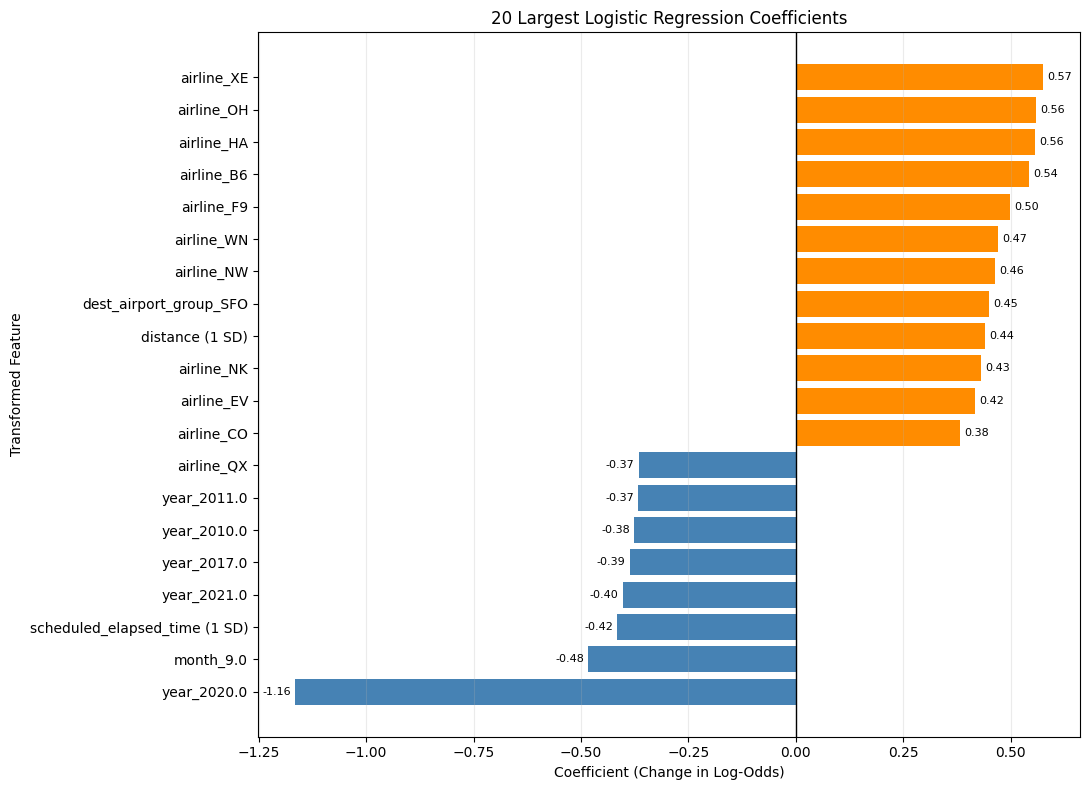

,feature,coefficient,odds_ratio
0,airline_XE,0.574,1.775
1,airline_OH,0.559,1.749
2,airline_HA,0.557,1.746
3,airline_B6,0.543,1.721
4,airline_F9,0.497,1.644
5,airline_WN,0.470,1.599
6,airline_NW,0.464,1.590
7,dest_airport_group_SFO,0.450,1.568
8,distance (1 SD),0.441,1.554
9,airline_NK,0.432,1.540


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve fitted logistic regression model
logistic_model = models["Logistic Regression"]

fitted_preprocessor = logistic_model.named_steps["features"]
fitted_classifier = logistic_model.named_steps["model"]

# Extract transformed feature names
feature_names = pd.Series(
    fitted_preprocessor.get_feature_names_out(),
    name="feature"
)

# Remove ColumnTransformer prefixes
feature_names = (
    feature_names
    .str.replace("numeric__", "", regex=False)
    .str.replace("categories__", "", regex=False)
)

# Rename numerical features to show standardization
feature_names = feature_names.replace({
    feature: f"{feature} (1 SD)"
    for feature in numerical_features
})

# Create coefficient table
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": fitted_classifier.coef_.ravel()
})

coefficient_table["odds_ratio"] = np.exp(
    coefficient_table["coefficient"]
)

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

# Identify reference categories
categorical_encoder = (
    fitted_preprocessor.named_transformers_["categories"]
)

reference_categories = pd.DataFrame({
    "categorical_feature": categorical_features,
    "reference_category": [
        categories[0]
        for categories in categorical_encoder.categories_
    ]
})

display(reference_categories)

# Select largest coefficients
N_COEFFICIENTS = 20

plot_coefficients = (
    coefficient_table
    .nlargest(N_COEFFICIENTS, "absolute_coefficient")
    .sort_values("coefficient")
)

# Select bar colors
colors = np.where(
    plot_coefficients["coefficient"] >= 0,
    "darkorange",
    "steelblue"
)

# Plot coefficients
fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    plot_coefficients["feature"],
    plot_coefficients["coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set(
    title=f"{N_COEFFICIENTS} Largest Logistic Regression Coefficients",
    xlabel="Coefficient (Change in Log-Odds)",
    ylabel="Transformed Feature"
)

ax.grid(axis="x", alpha=0.25)
ax.bar_label(
    bars,
    fmt="%.2f",
    padding=3,
    fontsize=8
)

plt.tight_layout()
plt.show()

# Display coefficient and odds-ratio table
display(
    plot_coefficients[
        ["feature", "coefficient", "odds_ratio"]
    ]
    .sort_values("coefficient", ascending=False)
    .reset_index(drop=True)
    .round(3)
)


In [10]:
results = []

for name in models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Log Loss": log_loss(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss
Model,,,,,,,
Majority Baseline,0.8062,0.0000,0.0000,0.0000,0.5000,0.1938,0.4918
Logistic Regression,0.8062,0.5000,0.0017,0.0035,0.6282,0.2822,0.4768
Balanced Logistic Regression,0.5879,0.2574,0.5976,0.3598,0.6272,0.2795,0.6683


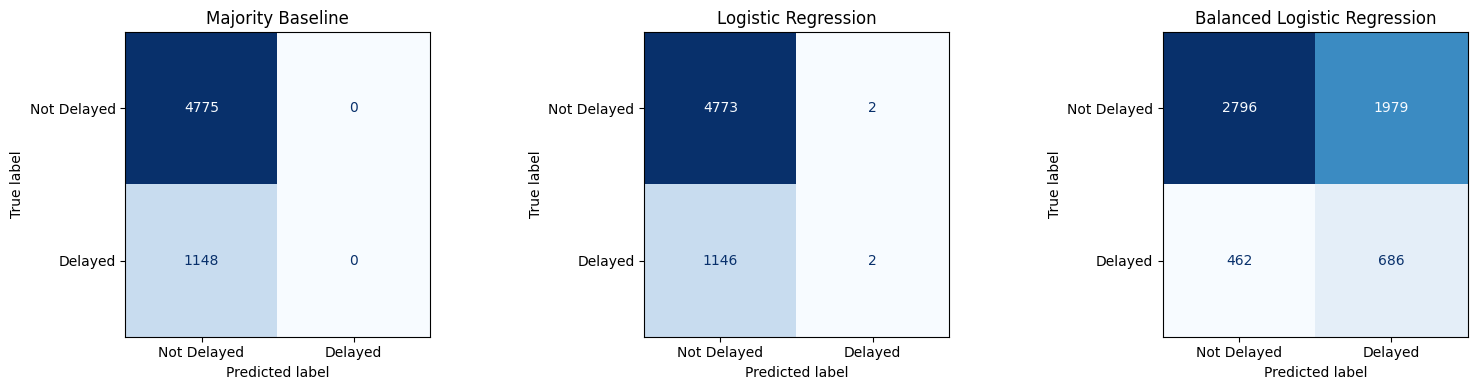

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Not Delayed", "Delayed"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

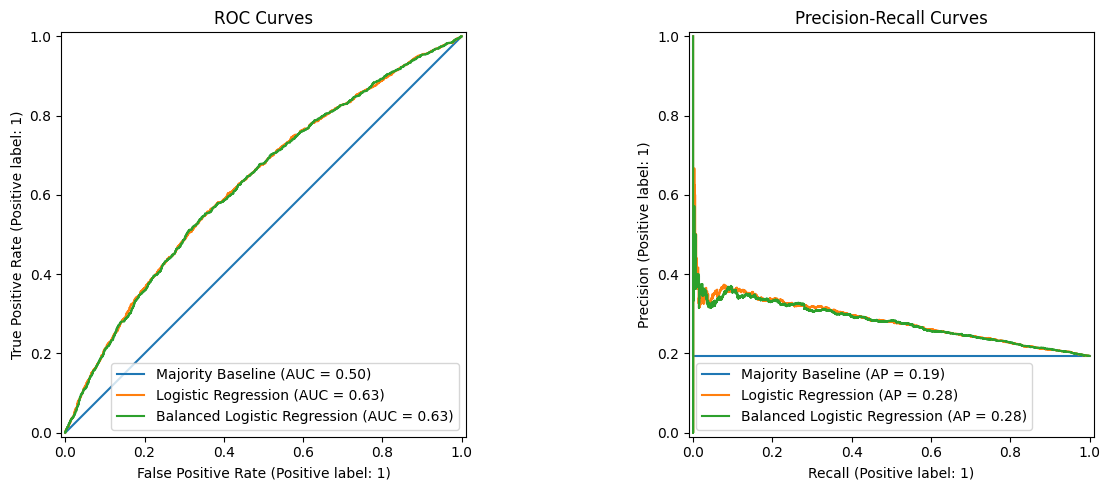

In [12]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, y_prob in probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=axes[1]
    )

axes[0].set_title("ROC Curves")
axes[1].set_title("Precision-Recall Curves")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = models["Logistic Regression"].predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.51, 0.05):

    y_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1
0,0.10,0.2014,0.9573,0.3328
1,0.15,0.2241,0.8153,0.3515
2,0.20,0.2604,0.6045,0.3640
3,0.25,0.2999,0.3885,0.3385
4,0.30,0.3338,0.1969,0.2477
5,0.35,0.3660,0.0845,0.1373
6,0.40,0.3529,0.0261,0.0487
7,0.45,0.4231,0.0096,0.0187
8,0.50,0.5000,0.0017,0.0035


In [14]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities using training data only
cv_prob = cross_val_predict(
    models["Logistic Regression"],
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=5
)[:, 1]

thresholds = np.arange(0.05, 0.51, 0.01)

results = []

for threshold in thresholds:
    pred = (cv_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0)
    })

cv_results = pd.DataFrame(results)

best = cv_results.loc[cv_results["F1"].idxmax()]

print("Best CV threshold:", round(best["Threshold"], 3))
print("CV F1:", round(best["F1"], 4))

Best CV threshold: 0.17
CV F1: 0.3702


Logistic Regression — Threshold = 0.17
              precision    recall  f1-score   support

 Not Delayed       0.88      0.43      0.58      4775
     Delayed       0.24      0.75      0.36      1148

    accuracy                           0.49      5923
   macro avg       0.56      0.59      0.47      5923
weighted avg       0.75      0.49      0.53      5923



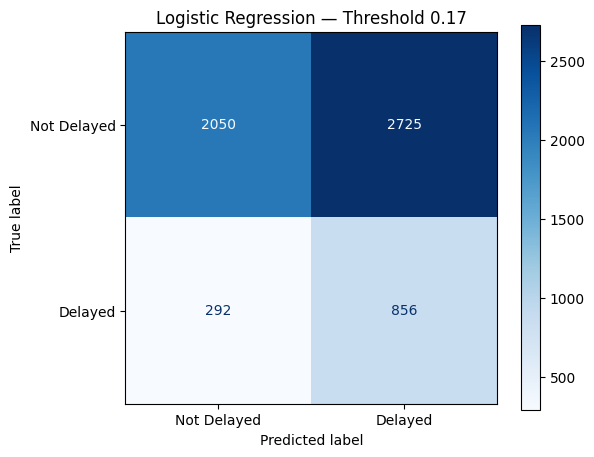

In [15]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import matplotlib.pyplot as plt
import pandas as pd

threshold = 0.17

# Standard logistic regression fitted earlier
logistic_model = models["Logistic Regression"]

# Generate test probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_pred = (y_prob >= threshold).astype(int)

# Classification report
print("Logistic Regression — Threshold = 0.17")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Delayed", "Delayed"],
    zero_division=0
))

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Delayed", "Delayed"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Logistic Regression — Threshold 0.17")

plt.show()


In [ ]:
logistic_results = []

for t in [0.50, 0.17]:

    pred = (y_prob >= t).astype(int)

    logistic_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob)
    })

display(pd.DataFrame(logistic_results).round(4))

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,0.50,0.8062,0.500,0.0017,0.0035,0.6282,0.2822
1,0.17,0.4906,0.239,0.7456,0.3620,0.6282,0.2822


# Logistic Regression: Predicting Significant Flight Delays

## 1. Research Objective

Our previous multiple linear regression models struggled to predict the exact duration of arrival delays. Even after introducing Ridge, Lasso, and Elastic Net regularization, the best model achieved an RMSE of approximately 37.58 minutes and an R² of only 0.0253. This indicated that our selected features explained only a small portion of the variation in arrival delay.

Rather than attempting to predict the exact number of minutes a flight would be delayed, we decided to investigate whether logistic regression could predict the **probability of a significant arrival delay**.

We defined our binary outcome as:

$$
Y =
\begin{cases}
1 & \text{if arrival delay} \geq 15 \text{ minutes}\\
0 & \text{if arrival delay} < 15 \text{ minutes}
\end{cases}
$$

We retained the same ten predictors from our linear regression analysis, including flight distance, scheduled flight times, airline, origin and destination airports, and calendar information. This allowed us to investigate whether the same predeparture information was more useful for predicting the occurrence of a delay than its exact duration.

## 2. Class Distribution and Imbalance

Before training the model, we examined the distribution of our binary outcome.

| Classification | Test observations | Proportion |
|---|---:|---:|
| Not significantly delayed (0) | 4,775 | 80.62% |
| Significantly delayed (1) | 1,148 | 19.38% |
| **Total** | **5,923** | **100%** |

Our dataset is imbalanced, with approximately four non-delayed flights for every delayed flight.

This creates a challenge when evaluating classification models. A model that predicts every flight will arrive on time could achieve **80.62% accuracy without identifying a single significantly delayed flight**.

For this reason, accuracy alone is insufficient to determine whether our logistic regression model is useful. We also considered precision, recall, F1-score, ROC-AUC, and Average Precision.

In particular, recall measures how many actual delayed flights we successfully identify, while precision measures how many of our predicted delays actually occur.

We retained the naturally occurring class distribution rather than artificially balancing the test data, ensuring that our evaluation reflected the observed frequency of delays.

## 3. Model Development

We trained three classification models:

1. **Majority Baseline:** Predicts the most common class, providing a minimum performance benchmark.
2. **Standard Logistic Regression:** Uses the original class distribution with L2 regularization.
3. **Balanced Logistic Regression:** Applies class weights inversely proportional to class frequency, giving delayed flights greater importance during optimization.

Numerical predictors were standardized using `StandardScaler`, while categorical predictors were transformed using one-hot encoding.

The models were fitted using our previously established training and testing datasets, preserving the same observations used in our earlier regression experiments.

Logistic regression estimates the probability of a significant delay through the logistic function:

$$
P(Y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\sum_{j=1}^{p}\beta_jX_j)}}
$$

A predicted probability is converted into a binary classification using a decision threshold, which defaults to 0.50.

## 4. Initial Classification Results

The initial classification reports revealed substantial differences between the standard and balanced logistic regression models.

| Metric | Majority baseline | Standard logistic | Balanced logistic |
|---|---:|---:|---:|
| Accuracy | 0.806 | 0.806 | 0.588 |
| Precision (delayed) | 0.000 | 0.500 | 0.257 |
| Recall (delayed) | 0.000 | 0.002 | 0.598 |
| F1-score (delayed) | 0.000 | 0.003 | 0.360 |
| ROC-AUC | 0.50 | 0.63 | 0.63 |
| Average Precision | 0.19 | 0.28 | 0.28 |

### Standard Logistic Regression

At the default classification threshold of 0.50, the standard logistic regression correctly identified only **2 of the 1,148 delayed flights**.

Although its accuracy was approximately 80.6%, nearly identical to the majority baseline, its recall was effectively zero.

This demonstrated that the model's apparently high accuracy was primarily a consequence of class imbalance rather than successful delay detection.

### Balanced Logistic Regression

Balanced logistic regression correctly identified **686 of the 1,148 delayed flights**, increasing recall to approximately 59.8%.

However, it also incorrectly classified 1,979 non-delayed flights as delayed, reducing overall accuracy to approximately 58.8%.

This revealed a trade-off between identifying delayed flights and producing false alarms. Class weighting substantially improved sensitivity to the minority class but did not automatically produce more accurate classifications overall.

## 5. ROC and Precision-Recall Analysis

Despite their different confusion matrices, standard and balanced logistic regression achieved nearly identical ROC-AUC values of approximately 0.63.

ROC-AUC evaluates how effectively a model ranks delayed flights above non-delayed flights across different classification thresholds. A value of 0.63 indicates modest predictive discrimination, outperforming random guessing but leaving considerable room for improvement.

The Precision-Recall curves produced similar findings.

The majority baseline achieved an Average Precision of approximately 0.19, reflecting the prevalence of significantly delayed flights. Both logistic regression models improved this to approximately 0.28.

These results suggest that our predictors contain some useful information for distinguishing delayed flights. However, neither logistic model demonstrates strong classification performance.

The nearly overlapping ROC and Precision-Recall curves also suggest that class weighting did not materially improve the models' ability to rank flights by delay risk.

Instead, the main difference between the models appeared in how those risk scores were converted into classifications.

## 6. Investigating Classification Thresholds

The initial results raised an important question: **Was standard logistic regression performing poorly because of its predictions, or because its default threshold of 0.50 was inappropriate for our imbalanced dataset?**

To investigate this, we evaluated precision, recall, and F1-score across several classification thresholds.

| Threshold | Precision | Recall | F1-score |
|---|---:|---:|---:|
| 0.10 | 0.2014 | 0.9573 | 0.3328 |
| 0.15 | 0.2241 | 0.8153 | 0.3515 |
| **0.20** | **0.2604** | **0.6045** | **0.3640** |
| 0.25 | 0.2999 | 0.3885 | 0.3385 |
| 0.30 | 0.3338 | 0.1969 | 0.2477 |
| 0.35 | 0.3660 | 0.0845 | 0.1373 |
| 0.40 | 0.3529 | 0.0261 | 0.0487 |
| 0.45 | 0.4231 | 0.0096 | 0.0187 |
| 0.50 | 0.5000 | 0.0017 | 0.0035 |

Lowering the classification threshold substantially increased recall because more flights were classified as potentially delayed.

At a threshold of 0.10, the model identified approximately 95.7% of delayed flights, but precision was only 20.1%, meaning most delay warnings were false alarms.

Increasing the threshold improved precision across much of the evaluated range but reduced recall, illustrating the fundamental precision-recall trade-off.

Among the thresholds examined on the test set, **0.20 produced the highest F1-score of 0.3640**.

At this threshold, the standard logistic regression identified approximately 60.5% of delayed flights with a precision of 26.0%. These results closely matched the balanced logistic regression at its default 0.50 threshold.

This demonstrated that adjusting the decision threshold could achieve similar classification performance without changing the model's class weights.

However, because these thresholds were explored using test observations, the resulting best threshold should be considered exploratory rather than a final independently validated selection.

## 7. Cross-Validation for Threshold Selection

To avoid choosing our final classification threshold directly from test-set performance, we used **5-fold stratified cross-validation on the training data**.

During cross-validation, the model generated out-of-fold predicted probabilities. Each training observation received a prediction from a model that had not been fitted on that observation.

We then evaluated candidate thresholds from 0.05 to 0.50 in increments of 0.01, selecting the threshold that maximized the F1-score.

Our results were:

| Metric | Result |
|---|---:|
| Selected CV threshold | **0.17** |
| Cross-validated F1-score | **0.3702** |
| Default threshold | 0.50 |

The selected threshold of 0.17 is substantially lower than the conventional default of 0.50, consistent with the imbalance in our dataset and our objective of identifying delayed flights.

This provides further evidence that the default decision threshold was poorly suited to our classification objective.

Cross-validation also helps reduce dependence on a single train-validation split. Nevertheless, the reported F1-score is the best score found during threshold selection and may be slightly optimistic. A separate evaluation is still needed to assess its generalization performance.

Because we previously examined the test-set threshold results, our final interpretation should also acknowledge that the overall experiment was exploratory.

## 8. Discussion of Findings

Our logistic regression analysis produced several important findings.

First, the class imbalance had a substantial effect on apparent model performance. At the default threshold, standard logistic regression achieved approximately 80.6% accuracy but failed to identify nearly every significantly delayed flight. This highlighted why accuracy alone can be misleading when the outcome of interest represents a minority of observations.

Second, both logistic regression models demonstrated modest discrimination, achieving ROC-AUC values of approximately 0.63 and Average Precision values of approximately 0.28. These improvements over their respective baselines suggest that scheduled flight information, airports, airlines, and calendar characteristics contain some predictive information about delay risk.

Third, modifying the classification threshold proved much more consequential for recall and F1-score than changing from standard to balanced logistic regression. The standard model's performance improved substantially when its threshold was lowered, despite leaving the fitted regression coefficients unchanged.

Finally, the cross-validation analysis selected a threshold of 0.17 with an F1-score of 0.3702. This establishes a training-based threshold choice that can be evaluated using the held-out test observations.

## 9. Limitations and Next Steps

Although logistic regression demonstrated some ability to identify delayed flights, its overall discrimination remained limited.

One possible limitation is the information available in our selected predictors. All features were chosen to represent information available before departure, meaning that unexpected weather events, operational disruptions, aircraft problems, and other developments may not be captured.

Another limitation is that logistic regression assumes the log-odds of a significant delay are linear in the encoded predictors. This may prevent the model from capturing nonlinear relationships and interactions between flight characteristics.

Our next steps are to evaluate the cross-validation-selected threshold of 0.17 on the held-out test data, examine the corresponding precision, recall, F1-score, and confusion matrix, and compare logistic regression with more flexible classification techniques.

Random Forest and Gradient Boosting would be useful candidates because they can capture nonlinear relationships and feature interactions without explicitly specifying polynomial terms.

We should also consider chronological validation to assess whether the model generalizes to future flights, rather than relying exclusively on randomly partitioned historical observations.

**Overall, the experiment demonstrates that reformulating arrival-delay prediction as a classification problem provides a useful alternative to continuous regression. However, changing the prediction objective does not eliminate the limitations imposed by the available features.**

### Evaluation of the Cross-Validated Classification Threshold

Following our initial logistic regression analysis, we evaluated the classification threshold of 0.17, selected through five-fold cross-validation on the training dataset. The objective was to improve the identification of significantly delayed flights while balancing precision and recall.

At the default threshold of 0.50, logistic regression achieved an accuracy of 80.62% but identified only 0.17% of significantly delayed flights. Reducing the threshold to 0.17 increased recall to 74.56%, correctly identifying 856 of the 1,148 delayed flights. However, precision decreased to 23.90%, with 2,725 non-delayed flights incorrectly classified as delayed.

The test F1-score increased from 0.0035 to 0.3620, closely matching the cross-validated F1-score of 0.3702. This suggests that the selected threshold produced reasonably consistent performance across training validation and test observations.

ROC-AUC remained unchanged at 0.6282, while Average Precision remained 0.2822. This was expected because adjusting the decision threshold changes classifications without improving the model's ability to rank flights by delay probability.

Overall, threshold optimization substantially improved delay detection but introduced a high number of false positives. Although logistic regression demonstrates modest predictive discrimination, further improvements will likely require models capable of capturing more complex relationships between the available predictors.